# Comptage de mots : Python simple, pseudo-MapReduce et Hadoop MapReduce

**Cours :** Fondements et Application de Big Data (13/10/2026, 8h-12h)
**Thème :** Hadoop MapReduce

## Consigne

| # | À faire |
|---|---------|
| 1 | Lire le document *Comptage des mots* |
| 2 | Étudier les trois méthodes proposées |
| 3 | Implémenter et tester chacune des méthodes (installer ce qu'il faut) |
| 4 | Comparer les 3 méthodes sur les mêmes fichiers (et de tailles différentes) |

**Génération des fichiers :**
- générer un fichier de **N lignes**, chaque ligne contenant **un mot** (avec répétition) ;
- générer un fichier plus gros de **m × N lignes** en dupliquant les N lignes **m fois** ;
- faire varier **m** pour obtenir des fichiers de plus en plus gros (attention au temps d'exécution).

**Rendu :** ce notebook, avec les explications, le code, les tests, les comparaisons et la conclusion.

## Plan

1. Environnement et outils
2. Principe de MapReduce
3. Génération des fichiers de test
4. Version 1 : Python simple
5. Version 2 : pseudo-MapReduce en Python
6. Version 3 : Hadoop MapReduce (cluster HDFS + YARN sous Docker)
7. Tests de justesse
8. Comparaison des performances
9. Analyse et conclusion

## 1. Environnement et outils

Le document de référence tourne sous Manjaro Linux avec Hadoop 3.4.0 installé à la main.
Ce notebook a été exécuté sous **Windows 11**, où Hadoop ne s'installe pas facilement en natif
(il lui faut `winutils.exe` et des bibliothèques natives). On utilise donc l'**image Docker officielle
d'Apache Hadoop** (`apache/hadoop:3.4.1`). Elle permet de monter un vrai petit cluster
**HDFS + YARN** (NameNode, DataNode, ResourceManager, NodeManager), comme dans le document.

Prérequis :
- Python ≥ 3.10 avec `jupyter`, `pandas` et `matplotlib` ;
- Docker Desktop (ou Docker Engine sous Linux) lancé, avec la commande `docker compose`.

La cellule suivante affiche la configuration réelle de la machine d'exécution.

In [1]:
import os, sys, platform, subprocess, time, random, gc, shutil, re
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

def sh(cmd, check=True, **kw):
    # Lance une commande shell et renvoie sa sortie standard (texte).
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", **kw)
    if check and r.returncode != 0:
        raise RuntimeError(f"Échec ({r.returncode}) : {cmd}\n{r.stdout[-2000:]}\n{r.stderr[-2000:]}")
    return r

print("Python     :", sys.version.split()[0])
print("Système    :", platform.platform())
print("Processeur :", platform.processor() or "?", "-", os.cpu_count(), "cœurs logiques")
print("pandas     :", pd.__version__)
r = sh("docker version --format {{.Server.Version}}", check=False)
print("Docker     :", r.stdout.strip() or "NON DISPONIBLE (la partie Hadoop sera sautée)")
DOCKER_OK = r.returncode == 0

Python     : 3.11.9
Système    : Windows-10-10.0.26300-SP0
Processeur : Intel64 Family 6 Model 154 Stepping 4, GenuineIntel - 12 cœurs logiques
pandas     : 2.3.0
Docker     : 28.4.0


## 2. Principe de MapReduce

MapReduce est un modèle de programmation pour traiter de gros volumes de données en parallèle.
Pour le comptage de mots :

```
           MAP                    SHUFFLE (tri / regroupement)          REDUCE
"chat"  -> (chat, 1)       \
"chien" -> (chien, 1)       >-->  chat  -> [1, 1]     ----------->  (chat, 2)
"chat"  -> (chat, 1)       /      chien -> [1]        ----------->  (chien, 1)
```

- **Map** : chaque ligne est transformée en paires clé/valeur `(mot, 1)`. Les lignes sont
  indépendantes, donc plusieurs machines peuvent traiter des morceaux différents du fichier.
- **Shuffle** : le framework regroupe toutes les valeurs d'une même clé (et les envoie au même reducer).
- **Reduce** : pour chaque clé, on agrège les valeurs (ici une somme).

Dans Hadoop, les données sont stockées dans **HDFS** (découpées en blocs de 128 Mo répliqués) et
les tâches sont ordonnancées par **YARN**. Un fichier de *k* blocs donne en principe *k* tâches map.

## 3. Génération des fichiers de test

Comme le demande la consigne :
1. on génère un fichier de base de **N lignes**, une ligne = un mot tiré au hasard dans un vocabulaire
   (donc avec répétitions). On reprend les 15 mots du document et on les tire avec des poids
   différents (loi de type Zipf) pour que les fréquences soient variées ;
2. on construit des fichiers de **m × N lignes** en recopiant le fichier de base **m fois** ;
3. on fait varier **m**.

La graine aléatoire est fixée : les fichiers sont identiques d'une exécution à l'autre.
Le contenu d'un gros fichier est connu à l'avance (chaque compte vaut *m* fois celui du fichier de base),
ce qui nous servira de test.

> ⚠️ Temps d'exécution : avec N = 100 000 et m = 200, le plus gros fichier fait 20 millions de lignes
> (environ 140 Mo). La version pseudo-MapReduce garde toutes les paires `(mot, 1)` en mémoire :
> compter 2 à 3 Go de RAM pour ce fichier. Réduire `M_VALUES` si la machine est plus modeste.

In [2]:
# Paramètres de l'expérience
N = 100_000                      # nombre de lignes du fichier de base
M_VALUES = [1, 10, 50, 100, 200]  # facteurs de duplication
SEED = 42

VOCABULAIRE = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne", "livre",
               "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

In [3]:
def generer_fichier_base(chemin, n, vocabulaire, seed=SEED):
    # Écrit n lignes, un mot par ligne, tiré avec remise (poids 1/rang : loi de type Zipf).
    rng = random.Random(seed)
    poids = [1 / (rang + 1) for rang in range(len(vocabulaire))]
    mots = rng.choices(vocabulaire, weights=poids, k=n)
    with open(chemin, "w", encoding="utf-8", newline="\n") as f:
        f.write("\n".join(mots) + "\n")
    return chemin


def dupliquer_fichier(source, destination, m):
    # Écrit m copies successives des lignes de `source` dans `destination` (m x N lignes).
    contenu = Path(source).read_bytes()
    with open(destination, "wb") as f:
        for _ in range(m):
            f.write(contenu)
    return destination


def compter_lignes(chemin):
    with open(chemin, "rb") as f:
        return sum(buf.count(b"\n") for buf in iter(lambda: f.read(1 << 20), b""))


fichier_base = generer_fichier_base(DATA_DIR / "mots.txt", N, VOCABULAIRE)

FICHIERS = {}
for m in M_VALUES:
    FICHIERS[m] = dupliquer_fichier(fichier_base, DATA_DIR / f"mots_m{m}.txt", m)

inventaire = pd.DataFrame([
    {"m": m, "fichier": str(p), "lignes": compter_lignes(p),
     "taille (Mo)": round(p.stat().st_size / 1e6, 2)}
    for m, p in FICHIERS.items()
])
inventaire

,m,fichier,lignes,taille (Mo)
0,1,data\mots_m1.txt,100000,0.59
1,10,data\mots_m10.txt,1000000,5.91
2,50,data\mots_m50.txt,5000000,29.54
3,100,data\mots_m100.txt,10000000,59.07
4,200,data\mots_m200.txt,20000000,118.14


In [4]:
# Aperçu du fichier de base : une ligne = un mot, avec répétitions
with open(fichier_base, encoding="utf-8") as f:
    print([next(f).strip() for _ in range(15)])

['maison', 'chat', 'chat', 'chat', 'soleil', 'maison', 'lune', 'chat', 'chien', 'chat', 'chat', 'arbre', 'chat', 'chat', 'maison']


## 4. Version 1 : Python simple

On lit **tout** le fichier en mémoire, on le découpe en mots avec `split()` et on compte
les occurrences dans un dictionnaire (`compteur.get(mot, 0) + 1`). C'est le code du document,
avec le nom du fichier passé en argument au lieu d'être écrit en dur.

- **Complexité :** O(n) en temps, une seule passe sur les mots.
- **Mémoire :** O(n) : le texte entier et la liste de tous les mots sont chargés d'un coup.
- **Parallélisme :** aucun, un seul cœur.

In [5]:
%%writefile wordcount.py
import sys


def compter_occurrences(fichier):
    with open(fichier, 'r', encoding='utf-8') as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur


if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "mots.txt"
    resultats = compter_occurrences(fichier)
    for mot, nb in sorted(resultats.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

Overwriting wordcount.py


Exécution du script en ligne de commande, chronométrée de bout en bout (comme `time python wordcount.py`
dans le document : ce temps inclut le démarrage de l'interpréteur Python).

In [6]:
t0 = time.perf_counter()
r = sh(f'"{sys.executable}" wordcount.py {fichier_base}')
print(r.stdout)
print(f"Temps total (démarrage de Python compris) : {time.perf_counter() - t0:.3f} s")

chat : 30137
chien : 15038
arbre : 10000
fleur : 7455
maison : 6103
soleil : 5003
montagne : 4375
livre : 3837
ciel : 3353
mer : 2968
lune : 2641
route : 2560
oiseau : 2308
jardin : 2197
voiture : 2025

Temps total (démarrage de Python compris) : 0.179 s


## 5. Version 2 : pseudo-MapReduce en Python

On reproduit **localement** les trois étapes du modèle avec trois fonctions :
- `mapper(ligne)` → liste de paires `(mot, 1)` ;
- `shuffle(paires)` → dictionnaire `mot -> [1, 1, ...]` ;
- `reducer(groupes)` → dictionnaire `mot -> somme`.

Le calcul reste séquentiel. On ne gagne rien en vitesse : on paie même un surcoût, puisque
toutes les paires intermédiaires sont créées puis stockées en mémoire. L'intérêt est de
**structurer** le calcul comme Hadoop le fera : `mapper` et `reducer` n'ont pas besoin de voir
tout le fichier, donc ils peuvent être distribués.

In [7]:
%%writefile mapreduce_wordcount.py
import sys
from collections import defaultdict


def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped


def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced


def compter_mapreduce(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    grouped = shuffle(mapped)
    return reducer(grouped)


if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "mots.txt"
    reduced = compter_mapreduce(fichier)
    for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {count}")

Overwriting mapreduce_wordcount.py


Les étapes intermédiaires sur un petit exemple, pour voir ce que produit chaque phase :

In [8]:
from mapreduce_wordcount import mapper, shuffle, reducer, compter_mapreduce
from wordcount import compter_occurrences

lignes = ["chat\n", "chien\n", "chat\n", "arbre\n", "chat\n"]
mapped = [paire for ligne in lignes for paire in mapper(ligne)]
grouped = shuffle(mapped)
print("MAP     :", mapped)
print("SHUFFLE :", dict(grouped))
print("REDUCE  :", reducer(grouped))

MAP     : [('chat', 1), ('chien', 1), ('chat', 1), ('arbre', 1), ('chat', 1)]
SHUFFLE : {'chat': [1, 1, 1], 'chien': [1], 'arbre': [1]}
REDUCE  : {'chat': 3, 'chien': 1, 'arbre': 1}


In [9]:
t0 = time.perf_counter()
r = sh(f'"{sys.executable}" mapreduce_wordcount.py {fichier_base}')
print(r.stdout)
print(f"Temps total (démarrage de Python compris) : {time.perf_counter() - t0:.3f} s")

chat : 30137
chien : 15038
arbre : 10000
fleur : 7455
maison : 6103
soleil : 5003
montagne : 4375
livre : 3837
ciel : 3353
mer : 2968
lune : 2641
route : 2560
oiseau : 2308
jardin : 2197
voiture : 2025

Temps total (démarrage de Python compris) : 0.281 s


## 6. Version 3 : Hadoop MapReduce

### 6.1 Installation : un cluster Hadoop sous Docker

Sous Linux, l'installation native du document suffit :

```bash
sudo pacman -S jdk-openjdk                       # (apt install openjdk-11-jdk sous Ubuntu)
wget https://archive.apache.org/dist/hadoop/common/hadoop-3.4.0/hadoop-3.4.0.tar.gz
tar -xvzf hadoop-3.4.0.tar.gz && mv hadoop-3.4.0 ~/hadoop
echo 'export HADOOP_HOME=$HOME/hadoop' >> ~/.bashrc && source ~/.bashrc
hdfs namenode -format && start-dfs.sh && start-yarn.sh
```

Ici, on utilise l'image officielle `apache/hadoop:3.4.1` et `docker compose`, qui lance
**4 conteneurs**, soit les 4 démons d'un cluster pseudo-distribué :

| Service | Rôle |
|---|---|
| `namenode` | HDFS : métadonnées (quels blocs, sur quel DataNode) ; interface web http://localhost:9870 |
| `datanode` | HDFS : stocke les blocs de données |
| `resourcemanager` | YARN : alloue les ressources aux jobs ; interface web http://localhost:8088 |
| `nodemanager` | YARN : exécute les tâches map et reduce dans des conteneurs |

La configuration (`core-site.xml`, `hdfs-site.xml`, `mapred-site.xml`, `yarn-site.xml`) passe
par des variables d'environnement que l'image convertit en fichiers XML. C'est la configuration
d'exemple de la documentation de l'image. Le dossier `data/` est monté dans le conteneur
`namenode` (en `/data`) pour y copier les fichiers vers HDFS.

In [10]:
HADOOP_IMAGE = "apache/hadoop:3.4.1"
HADOOP_DIR = Path("hadoop")
HADOOP_DIR.mkdir(exist_ok=True)

(HADOOP_DIR / "config").write_text('''\
CORE-SITE.XML_fs.default.name=hdfs://namenode
CORE-SITE.XML_fs.defaultFS=hdfs://namenode
HDFS-SITE.XML_dfs.namenode.rpc-address=namenode:8020
HDFS-SITE.XML_dfs.replication=1
MAPRED-SITE.XML_mapreduce.framework.name=yarn
MAPRED-SITE.XML_yarn.app.mapreduce.am.env=HADOOP_MAPRED_HOME=/opt/hadoop
MAPRED-SITE.XML_mapreduce.map.env=HADOOP_MAPRED_HOME=/opt/hadoop
MAPRED-SITE.XML_mapreduce.reduce.env=HADOOP_MAPRED_HOME=/opt/hadoop
YARN-SITE.XML_yarn.resourcemanager.hostname=resourcemanager
YARN-SITE.XML_yarn.nodemanager.pmem-check-enabled=false
YARN-SITE.XML_yarn.nodemanager.delete.debug-delay-sec=600
YARN-SITE.XML_yarn.nodemanager.vmem-check-enabled=false
YARN-SITE.XML_yarn.nodemanager.aux-services=mapreduce_shuffle
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.maximum-applications=10000
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.maximum-am-resource-percent=0.1
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.resource-calculator=org.apache.hadoop.yarn.util.resource.DefaultResourceCalculator
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.queues=default
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.capacity=100
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.user-limit-factor=1
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.maximum-capacity=100
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.state=RUNNING
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.acl_submit_applications=*
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.root.default.acl_administer_queue=*
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.node-locality-delay=40
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.queue-mappings=
CAPACITY-SCHEDULER.XML_yarn.scheduler.capacity.queue-mappings-override.enable=false
''', encoding="utf-8")

(HADOOP_DIR / "docker-compose.yml").write_text(f'''\
name: tp-hadoop
services:
  namenode:
    image: {HADOOP_IMAGE}
    hostname: namenode
    command: ["hdfs", "namenode"]
    ports: ["9870:9870"]
    env_file: ./config
    environment:
      ENSURE_NAMENODE_DIR: "/tmp/hadoop-root/dfs/name"
    volumes:
      - ../data:/data
  datanode:
    image: {HADOOP_IMAGE}
    command: ["hdfs", "datanode"]
    env_file: ./config
    depends_on: [namenode]
  resourcemanager:
    image: {HADOOP_IMAGE}
    hostname: resourcemanager
    command: ["yarn", "resourcemanager"]
    ports: ["8088:8088"]
    env_file: ./config
  nodemanager:
    image: {HADOOP_IMAGE}
    command: ["yarn", "nodemanager"]
    env_file: ./config
    depends_on: [resourcemanager]
''', encoding="utf-8")

COMPOSE = f'docker compose -f "{HADOOP_DIR / "docker-compose.yml"}"'
print((HADOOP_DIR / "docker-compose.yml").read_text())

name: tp-hadoop
services:
  namenode:
    image: apache/hadoop:3.4.1
    hostname: namenode
    command: ["hdfs", "namenode"]
    ports: ["9870:9870"]
    env_file: ./config
    environment:
      ENSURE_NAMENODE_DIR: "/tmp/hadoop-root/dfs/name"
    volumes:
      - ../data:/data
  datanode:
    image: apache/hadoop:3.4.1
    command: ["hdfs", "datanode"]
    env_file: ./config
    depends_on: [namenode]
  resourcemanager:
    image: apache/hadoop:3.4.1
    hostname: resourcemanager
    command: ["yarn", "resourcemanager"]
    ports: ["8088:8088"]
    env_file: ./config
  nodemanager:
    image: apache/hadoop:3.4.1
    command: ["yarn", "nodemanager"]
    env_file: ./config
    depends_on: [resourcemanager]



Démarrage du cluster (le premier lancement télécharge l'image, environ 1 Go). On attend ensuite
que HDFS soit sorti du *safe mode*, qu'un DataNode soit enregistré et qu'un NodeManager soit
disponible dans YARN.

In [11]:
def hexec(cmd, check=True):
    # Exécute une commande dans le conteneur namenode (client Hadoop configuré).
    return sh(f"{COMPOSE} exec -T namenode bash -c \"{cmd}\"", check=check)


def attendre_cluster(timeout=240):
    t0 = time.time()
    while time.time() - t0 < timeout:
        hdfs = hexec("hdfs dfsadmin -safemode get 2>/dev/null; hdfs dfsadmin -report 2>/dev/null | grep 'Live datanodes'", check=False).stdout
        yarn = hexec("yarn node -list 2>/dev/null | grep -c RUNNING", check=False).stdout.strip()
        if "Safe mode is OFF" in hdfs and "Live datanodes (1)" in hdfs and yarn.isdigit() and int(yarn) >= 1:
            return time.time() - t0
        time.sleep(3)
    raise TimeoutError("Le cluster Hadoop n'a pas démarré à temps :\n" + hdfs + "\nYARN : " + yarn)


if DOCKER_OK:
    t0 = time.perf_counter()
    sh(f"{COMPOSE} up -d")
    attente = attendre_cluster()
    print(f"Cluster prêt en {time.perf_counter() - t0:.1f} s")
    print(sh(f"{COMPOSE} ps --format \"table {{{{.Service}}}}\t{{{{.Status}}}}\"").stdout)
    print(hexec("hadoop version | head -1").stdout)

Cluster prêt en 34.1 s


SERVICE           STATUS
datanode          Up 32 seconds
namenode          Up 33 seconds
nodemanager       Up 32 seconds
resourcemanager   Up 33 seconds



Hadoop 3.4.1



### 6.2 Exécution du job

Les trois étapes du document :
1. créer un répertoire dans HDFS et y copier le fichier (`hdfs dfs -put`) ;
2. lancer le job `wordcount` du jar d'exemples livré avec Hadoop (`hadoop jar ... wordcount entrée sortie`) ;
3. lire le résultat (`hdfs dfs -cat .../part-r-00000`).

Le programme `wordcount` du jar est la classe Java `WordCount` : un `Mapper` qui émet `(mot, 1)`,
un `Combiner` qui fait des sommes partielles **côté map** (moins de données à transférer
pendant le shuffle) et un `Reducer` qui fait la somme finale.

On chronomètre séparément la copie dans HDFS et le job : on veut comparer le calcul,
pas le transfert de fichier.

In [12]:
JAR = "/opt/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar"
HDFS_BASE = "/user/root/wordcount"


def hadoop_put(fichier_local):
    # Copie data/<fichier> dans HDFS ; renvoie (chemin HDFS, durée en s).
    nom = Path(fichier_local).name
    t0 = time.perf_counter()
    hexec(f"hdfs dfs -mkdir -p {HDFS_BASE}/input && hdfs dfs -put -f /data/{nom} {HDFS_BASE}/input/{nom}")
    return f"{HDFS_BASE}/input/{nom}", time.perf_counter() - t0


def hadoop_wordcount(chemin_hdfs, nom_sortie):
    # Lance le job wordcount ; renvoie (comptes, durée en s, nombre de tâches map).
    sortie = f"{HDFS_BASE}/output_{nom_sortie}"
    hexec(f"hdfs dfs -rm -r -f -skipTrash {sortie}")
    t0 = time.perf_counter()
    r = hexec(f"hadoop jar {JAR} wordcount {chemin_hdfs} {sortie} 2>&1")
    duree = time.perf_counter() - t0
    if not re.search(r"Job job_\S+ completed successfully", r.stdout):
        raise RuntimeError("Le job Hadoop a échoué :\n" + r.stdout[-3000:])
    maps = re.search(r"Launched map tasks=(\d+)", r.stdout)
    sortie_txt = hexec(f"hdfs dfs -cat {sortie}/part-r-*").stdout
    comptes = {}
    for ligne in sortie_txt.splitlines():
        mot, nb = ligne.rsplit("\t", 1)
        comptes[mot] = int(nb)
    return comptes, duree, int(maps.group(1)) if maps else None, r.stdout


if DOCKER_OK:
    chemin, t_put = hadoop_put(fichier_base)
    comptes_hadoop, t_job, n_maps, journal = hadoop_wordcount(chemin, "base")
    print(f"hdfs dfs -put : {t_put:.2f} s   |   job wordcount : {t_job:.2f} s   |   tâches map : {n_maps}\n")
    for mot, nb in sorted(comptes_hadoop.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

hdfs dfs -put : 7.80 s   |   job wordcount : 37.71 s   |   tâches map : 1

chat : 30137
chien : 15038
arbre : 10000
fleur : 7455
maison : 6103
soleil : 5003
montagne : 4375
livre : 3837
ciel : 3353
mer : 2968
lune : 2641
route : 2560
oiseau : 2308
jardin : 2197
voiture : 2025


Extrait du journal du job (identifiant de l'application YARN, état final, compteurs) :

In [13]:
if DOCKER_OK:
    garder = ("Submitted application", "Running job", "completed successfully", "map 100%",
              "Launched map tasks", "Launched reduce tasks", "Map input records",
              "Map output records", "Combine output records", "Reduce input records",
              "Reduce output records", "Bytes Read=", "Bytes Written=")
    print("\n".join(l.strip() for l in journal.splitlines() if any(g in l for g in garder)))

2026-10-13 08:18:05 INFO  YarnClientImpl:356 - Submitted application application_1791879449192_0001
2026-10-13 08:18:05 INFO  Job:1726 - Running job: job_1791879449192_0001
2026-10-13 08:18:28 INFO  Job:1754 -  map 100% reduce 0%
2026-10-13 08:18:33 INFO  Job:1754 -  map 100% reduce 100%
2026-10-13 08:18:34 INFO  Job:1765 - Job job_1791879449192_0001 completed successfully
Launched map tasks=1
Launched reduce tasks=1
Map input records=100000
Map output records=100000
Combine output records=15
Reduce input records=15
Reduce output records=15
Bytes Read=590719
Bytes Written=172


Le compteur `Combine output records` montre l'effet du **combiner** : les N paires `(mot, 1)`
émises par les mappers sont réduites à quelques dizaines de paires avant le shuffle
(`Reduce input records`). C'est une optimisation absente de notre pseudo-MapReduce.

## 7. Tests de justesse

Avant de comparer les temps, on vérifie que les trois méthodes calculent **la même chose et
le bon résultat** :

1. **Tests unitaires** sur de petits fichiers dont on connaît le résultat, cas limites compris
   (fichier vide, lignes vides, espaces en trop, plusieurs mots par ligne, accents) ;
2. **Référence indépendante** : comparaison avec `collections.Counter` de la bibliothèque standard ;
3. **Propriété de la duplication** : un fichier formé de m copies doit donner exactement
   m × les comptes du fichier de base ;
4. **Hadoop = Python** : le résultat du cluster doit être identique à celui des versions Python
   (vérifié pour chaque taille dans la partie 8).

In [14]:
TESTS_DIR = DATA_DIR / "tests"
TESTS_DIR.mkdir(exist_ok=True)

CAS = {
    "simple":        ("chat\nchien\nchat\n",                {"chat": 2, "chien": 1}),
    "vide":          ("",                                   {}),
    "lignes_vides":  ("\n\nchat\n\n\nchat\n",               {"chat": 2}),
    "espaces":       ("  chat  \n\tchien\t\nchat",          {"chat": 2, "chien": 1}),
    "plusieurs":     ("chat chien\nchien chien oiseau\n",   {"chat": 1, "chien": 3, "oiseau": 1}),
    "accents":       ("été\nÉté\nété\n",                    {"été": 2, "Été": 1}),
}

for nom, (contenu, attendu) in CAS.items():
    chemin = TESTS_DIR / f"{nom}.txt"
    chemin.write_text(contenu, encoding="utf-8")
    assert compter_occurrences(chemin) == attendu, f"V1 échoue sur {nom}"
    assert compter_mapreduce(chemin) == attendu, f"V2 échoue sur {nom}"
    print(f"OK  {nom:<13} -> {attendu}")

OK  simple        -> {'chat': 2, 'chien': 1}
OK  vide          -> {}
OK  lignes_vides  -> {'chat': 2}
OK  espaces       -> {'chat': 2, 'chien': 1}
OK  plusieurs     -> {'chat': 1, 'chien': 3, 'oiseau': 1}
OK  accents       -> {'été': 2, 'Été': 1}


Remarque : le comptage est sensible à la casse (`été` ≠ `Été`), comme le `wordcount` de Hadoop.
Les trois méthodes découpent sur les blancs (espaces, tabulations, retours à la ligne).

In [15]:
# Référence indépendante + propriété de duplication, sur tous les fichiers générés
with open(fichier_base, encoding="utf-8") as f:
    reference_base = Counter(f.read().split())

assert sum(reference_base.values()) == N
assert compter_occurrences(fichier_base) == reference_base
assert compter_mapreduce(fichier_base) == reference_base
print("Fichier de base : V1 = V2 = Counter  ->", dict(reference_base.most_common(5)), "...")

for m in [m for m in M_VALUES if m <= 10]:   # les gros fichiers sont vérifiés en partie 8
    attendu = {mot: m * nb for mot, nb in reference_base.items()}
    assert compter_occurrences(FICHIERS[m]) == attendu
    assert compter_mapreduce(FICHIERS[m]) == attendu
    print(f"m = {m:>3} : comptes = {m} x comptes de base  OK")

if DOCKER_OK:
    assert comptes_hadoop == reference_base
    print("Hadoop (fichier de base) = Counter  OK")

Fichier de base : V1 = V2 = Counter  ->

 {'chat': 30137, 'chien': 15038, 'arbre': 10000, 'fleur': 7455, 'maison': 6103} ...


m =   1 : comptes = 1 x comptes de base  OK


m =  10 : comptes = 10 x comptes de base  OK
Hadoop (fichier de base) = Counter  OK


**Preuve que les tests détectent une erreur.** Un test qui ne peut pas échouer ne prouve rien :
on injecte volontairement une faute (un reducer qui oublie la dernière valeur) et on vérifie
que la comparaison la repère.

In [16]:
def reducer_faux(grouped_data):
    return {mot: sum(valeurs[:-1]) for mot, valeurs in grouped_data.items()}

mapped = [p for ligne in open(TESTS_DIR / "simple.txt", encoding="utf-8") for p in mapper(ligne)]
resultat_faux = reducer_faux(shuffle(mapped))
assert resultat_faux != CAS["simple"][1]
print("Faute injectée détectée :", resultat_faux, "!=", CAS["simple"][1])

Faute injectée détectée : {'chat': 1, 'chien': 0} != {'chat': 2, 'chien': 1}


## 8. Comparaison des performances

Pour chaque fichier (m × N lignes), on mesure :
- **V1** et **V2** : temps du calcul seul, mesuré dans le notebook avec `time.perf_counter()`
  (meilleur de 3 essais pour les petits fichiers, un seul essai au-delà d'un million de lignes) ;
- **V3 Hadoop** : temps réel de la commande `hadoop jar ... wordcount` (soumission à YARN, démarrage
  des JVM, map, shuffle, reduce, écriture dans HDFS) ; la copie dans HDFS (`put`) est notée à part.

Pour chaque taille, on vérifie aussi que les trois résultats sont identiques et valent m × la référence.

In [17]:
def chronometrer(fonction, fichier, essais):
    meilleur, resultat = float("inf"), None
    for _ in range(essais):
        gc.collect()
        t0 = time.perf_counter()
        resultat = fonction(fichier)
        meilleur = min(meilleur, time.perf_counter() - t0)
    return meilleur, resultat


mesures = []
for m, fichier in FICHIERS.items():
    lignes = m * N
    essais = 3 if lignes <= 1_000_000 else 1
    attendu = {mot: m * nb for mot, nb in reference_base.items()}

    t_v1, res_v1 = chronometrer(compter_occurrences, fichier, essais)
    assert res_v1 == attendu, f"V1 faux pour m={m}"
    del res_v1

    t_v2, res_v2 = chronometrer(compter_mapreduce, fichier, essais)
    assert res_v2 == attendu, f"V2 faux pour m={m}"
    del res_v2
    gc.collect()

    ligne = {"m": m, "lignes": lignes, "taille (Mo)": round(fichier.stat().st_size / 1e6, 1),
             "V1 Python simple (s)": t_v1, "V2 pseudo-MapReduce (s)": t_v2}

    if DOCKER_OK:
        chemin, t_put = hadoop_put(fichier)
        res_v3, t_v3, n_maps, _ = hadoop_wordcount(chemin, f"m{m}")
        assert res_v3 == attendu, f"Hadoop faux pour m={m}"
        ligne.update({"V3 Hadoop job (s)": t_v3, "HDFS put (s)": t_put, "tâches map": n_maps})

    mesures.append(ligne)
    print(f"m={m:>4} ({lignes:>11,} lignes) : V1 {t_v1:7.3f} s | V2 {t_v2:7.3f} s"
          + (f" | Hadoop {t_v3:6.1f} s ({n_maps} map)" if DOCKER_OK else "") + "  -> résultats identiques")

resultats = pd.DataFrame(mesures).set_index("m")
resultats.round(3)

m=   1 (    100,000 lignes) : V1   0.015 s | V2   0.067 s | Hadoop   31.5 s (1 map)  -> résultats identiques


m=  10 (  1,000,000 lignes) : V1   0.219 s | V2   0.782 s | Hadoop   31.7 s (1 map)  -> résultats identiques


m=  50 (  5,000,000 lignes) : V1   1.455 s | V2   4.728 s | Hadoop   38.6 s (1 map)  -> résultats identiques


m= 100 ( 10,000,000 lignes) : V1   2.907 s | V2  10.847 s | Hadoop   40.7 s (1 map)  -> résultats identiques


m= 200 ( 20,000,000 lignes) : V1   7.176 s | V2  20.513 s | Hadoop   56.1 s (1 map)  -> résultats identiques


,lignes,taille (Mo),V1 Python simple (s),V2 pseudo-MapReduce (s),V3 Hadoop job (s),HDFS put (s),tâches map
m,,,,,,,
1,100000,0.6,0.015,0.067,31.485,7.063,1
10,1000000,5.9,0.219,0.782,31.698,6.469,1
50,5000000,29.5,1.455,4.728,38.575,10.681,1
100,10000000,59.1,2.907,10.847,40.749,13.175,1
200,20000000,118.1,7.176,20.513,56.059,23.414,1


In [18]:
cols = [c for c in ["V1 Python simple (s)", "V2 pseudo-MapReduce (s)", "V3 Hadoop job (s)"] if c in resultats]
debits = pd.DataFrame({c.split(" (")[0]: resultats["lignes"] / resultats[c] / 1e6 for c in cols})
debits.columns = [f"{c} (M lignes/s)" for c in debits.columns]
rapports = pd.DataFrame({"V2 / V1": resultats["V2 pseudo-MapReduce (s)"] / resultats["V1 Python simple (s)"]})
if "V3 Hadoop job (s)" in resultats:
    rapports["V3 / V1"] = resultats["V3 Hadoop job (s)"] / resultats["V1 Python simple (s)"]
pd.concat([debits, rapports], axis=1).round(2)

,V1 Python simple (M lignes/s),V2 pseudo-MapReduce (M lignes/s),V3 Hadoop job (M lignes/s),V2 / V1,V3 / V1
m,,,,,
1,6.73,1.49,0.00,4.52,2117.35
10,4.57,1.28,0.03,3.58,144.99
50,3.44,1.06,0.13,3.25,26.51
100,3.44,0.92,0.25,3.73,14.02
200,2.79,0.97,0.36,2.86,7.81


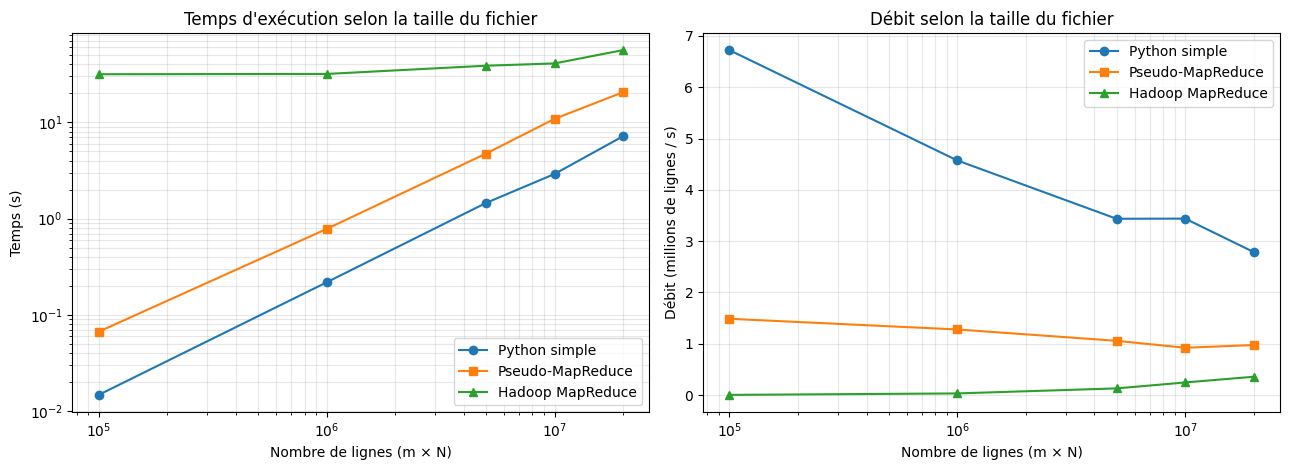

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
styles = {"V1 Python simple (s)": ("o-", "Python simple"),
          "V2 pseudo-MapReduce (s)": ("s-", "Pseudo-MapReduce"),
          "V3 Hadoop job (s)": ("^-", "Hadoop MapReduce")}
for c in cols:
    ax1.plot(resultats["lignes"], resultats[c], styles[c][0], label=styles[c][1])
    ax2.plot(resultats["lignes"], resultats["lignes"] / resultats[c] / 1e6, styles[c][0], label=styles[c][1])

ax1.set(xscale="log", yscale="log", xlabel="Nombre de lignes (m × N)", ylabel="Temps (s)",
        title="Temps d'exécution selon la taille du fichier")
ax2.set(xscale="log", xlabel="Nombre de lignes (m × N)", ylabel="Débit (millions de lignes / s)",
        title="Débit selon la taille du fichier")
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 8.2 Le parallélisme de Hadoop : effet de la taille des blocs HDFS

Dans le tableau ci-dessus, chaque job n'a lancé **qu'une seule tâche map** : même le plus gros fichier
tient dans un seul bloc HDFS (128 Mo par défaut). Hadoop n'a donc jamais travaillé en parallèle.

Pour le voir paralléliser sur la même machine, on recopie le plus gros fichier dans HDFS avec des blocs
plus petits (`hdfs dfs -D dfs.blocksize=... -put`). Il y a une tâche map par bloc, et YARN en exécute
plusieurs en même temps (le NodeManager dispose de 8 cœurs virtuels par défaut).

In [20]:
if DOCKER_OK:
    m_max = max(M_VALUES)
    gros = FICHIERS[m_max]
    attendu_gros = {mot: m_max * nb for mot, nb in reference_base.items()}
    essais_blocs = []
    for bloc_mo in [128, 64, 32, 16]:
        dossier = f"{HDFS_BASE}/input_bloc{bloc_mo}"
        hexec(f"hdfs dfs -mkdir -p {dossier} && hdfs dfs -D dfs.blocksize={bloc_mo}m -put -f /data/{gros.name} {dossier}/")
        res, t, n_maps, _ = hadoop_wordcount(f"{dossier}/{gros.name}", f"bloc{bloc_mo}")
        assert res == attendu_gros, f"Hadoop faux avec des blocs de {bloc_mo} Mo"
        essais_blocs.append({"taille de bloc (Mo)": bloc_mo, "tâches map": n_maps, "V3 Hadoop job (s)": round(t, 1)})
        print(f"blocs de {bloc_mo:>3} Mo : {n_maps} tâches map, {t:5.1f} s  -> résultat identique")
    blocs = pd.DataFrame(essais_blocs).set_index("taille de bloc (Mo)")
    blocs["V1 Python simple (s)"] = round(resultats.loc[m_max, "V1 Python simple (s)"], 2)
    display(blocs)

blocs de 128 Mo : 1 tâches map,  54.5 s  -> résultat identique


blocs de  64 Mo : 2 tâches map,  49.0 s  -> résultat identique


blocs de  32 Mo : 5 tâches map,  55.5 s  -> résultat identique


blocs de  16 Mo : 7 tâches map,  64.8 s  -> résultat identique


,tâches map,V3 Hadoop job (s),V1 Python simple (s)
taille de bloc (Mo),,,
128,1,54.5,7.18
64,2,49.0,7.18
32,5,55.5,7.18
16,7,64.8,7.18


## 9. Analyse et conclusion

*Les chiffres ci-dessous viennent de l'exécution de ce notebook (Windows 11, 12 cœurs logiques,
Hadoop 3.4.1 sous Docker). Ils varient de quelques pourcents d'une exécution à l'autre ; les ordres
de grandeur, eux, restent stables.*

### 9.1 Justesse

Les trois méthodes donnent **exactement les mêmes comptes** sur tous les fichiers, de 100 000 à
20 millions de lignes, et ces comptes valent bien m × ceux du fichier de base (vérifié par `assert`
à chaque taille). Les cas limites (fichier vide, lignes vides, espaces, accents) passent, et une
faute volontairement injectée est bien détectée.

### 9.2 Performances

| Fichier | V1 Python simple | V2 pseudo-MapReduce | V3 Hadoop (job) | Hadoop / V1 |
|---|---|---|---|---|
| 100 000 lignes (0,6 Mo) | 0,015 s | 0,067 s | 31,5 s | × 2 100 |
| 1 M lignes (5,9 Mo) | 0,22 s | 0,78 s | 31,7 s | × 145 |
| 5 M lignes (29,5 Mo) | 1,46 s | 4,73 s | 38,6 s | × 27 |
| 10 M lignes (59 Mo) | 2,91 s | 10,8 s | 40,7 s | × 14 |
| 20 M lignes (118 Mo) | 7,18 s | 20,5 s | 56,1 s | × 7,8 |

1. **Python simple (V1)** est la plus rapide à toutes les tailles testées, avec environ 3 millions de
   lignes par seconde. Son temps croît linéairement avec la taille. Sa limite est la mémoire :
   `f.read().split()` charge tout le fichier et la liste de tous ses mots en RAM.

2. **Pseudo-MapReduce (V2)** donne les mêmes résultats, mais **3 à 4 fois plus lentement** que V1.
   Elle crée une paire `(mot, 1)` par mot, les garde toutes en mémoire, puis les regroupe en
   listes avant de les sommer. Elle ne gagne rien en échange, puisqu'elle tourne sur un seul
   processus. Son intérêt est pédagogique : elle découpe le calcul en `mapper` / `shuffle` / `reducer`,
   la forme qui permet de le distribuer.

3. **Hadoop (V3)** coûte environ **30 s fixes**, quelle que soit la taille : soumission à YARN,
   démarrage de l'ApplicationMaster et des JVM des tâches, écriture du résultat dans HDFS. C'est le
   même phénomène que dans le document (12 s sur une installation Linux native). Sous Docker/Windows,
   ce coût est plus élevé. Ensuite, le temps de calcul marginal reste faible : entre 0,1 M et 20 M
   lignes, le job ne prend que 25 s de plus. L'écart avec Python se réduit donc vite quand la taille
   augmente (de × 2 100 à × 7,8). À cela s'ajoute la copie dans HDFS (`put`), de 7 à 23 s.

4. **Le parallélisme (partie 8.2)** n'apporte presque rien sur une seule machine. Avec des blocs plus
   petits, Hadoop lance bien plus de tâches map (1 → 7), mais le temps passe seulement de 54,5 s
   à 49 s (2 maps), puis remonte (64,8 s avec 7 maps). Toutes les tâches se partagent les mêmes
   cœurs et la même mémoire, celles de la machine virtuelle Docker. Et chaque tâche supplémentaire
   coûte le démarrage d'une JVM. Le parallélisme de Hadoop n'est rentable que s'il ajoute de vraies
   machines.

### 9.3 Quand utiliser quoi ?

| Critère | Python simple | Pseudo-MapReduce | Hadoop MapReduce |
|---|---|---|---|
| Petits et moyens fichiers (< quelques Go) | ✅ le meilleur choix | ➖ plus lent, sans gain | ❌ ~30 s de latence fixe |
| Fichier plus gros que la RAM | ❌ tout est chargé en mémoire | ❌ toutes les paires en mémoire | ✅ traitement en flux, bloc par bloc |
| Plusieurs machines | ❌ | ❌ | ✅ un map par bloc, sur le nœud qui a la donnée |
| Tolérance aux pannes | ❌ | ❌ | ✅ réplication HDFS, relance des tâches |
| Simplicité de mise en place | ✅ 10 lignes | ✅ | ❌ cluster HDFS + YARN à installer |

### 9.4 Conclusion

Sur une seule machine, avec des fichiers de quelques centaines de mégaoctets, **la version Python
simple est imbattable**. Hadoop reste ici 8 à 2 000 fois plus lent, car son coût de démarrage
(environ 30 s) écrase le temps de calcul. La version pseudo-MapReduce montre que la décomposition
map / shuffle / reduce ne rend pas un programme plus rapide : elle ajoute des données intermédiaires.
Elle le rend **distribuable**.

C'est ce que Hadoop exploite. Quand les données ne tiennent plus dans la mémoire, ni même sur le
disque d'une seule machine (plusieurs centaines de Go ou des To), et qu'on dispose d'un cluster,
le coût fixe devient négligeable. Chaque nœud traite alors ses propres blocs en parallèle, et le
**combiner** réduit le volume échangé pendant le shuffle (sur le fichier de base, les 100 000 paires
`(mot, 1)` deviennent 15 paires avant le shuffle). Les trois versions forment une progression : comprendre le
calcul (V1), le reformuler en MapReduce (V2), puis le distribuer réellement (V3).

**Limites de l'expérience :** un seul nœud (sous Docker sur Windows), donc aucun gain réel de
parallélisme. Des fichiers d'au plus 118 Mo, pour garder la version pseudo-MapReduce dans la RAM
disponible. Un vocabulaire de 15 mots seulement : avec un vrai texte et des milliers de mots
différents, le shuffle de Hadoop pèserait davantage.

### Nettoyage

Arrêter le cluster Hadoop et supprimer ses conteneurs (passer `ARRETER` à `True`). Les fichiers
générés sont dans `data/` (environ 300 Mo) : on peut les effacer à la main.

In [21]:
ARRETER = False
if DOCKER_OK and ARRETER:
    print(sh(f"{COMPOSE} down").stderr)